# 01 - Exploratory data analysis (2026 MLB, 30 teams)

Descriptive checks before interpreting H1-H3. Logic lives in `src/`; this notebook only imports and displays. Metric definitions: `docs/metrics.md` (frozen).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import hypotheses as H
from src.viz import plots

%matplotlib inline
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

games = pd.read_parquet(ROOT / "data/processed/team_games.parquet")
d = H.prepare(pd.read_parquet(ROOT / "data/processed/team_season.parquet"))
print(games.shape, d.shape)

(4858, 9) (30, 37)


## 1. Sanity checks

In [2]:
print("teams:", d.team.nunique(), "| games per team:", d.games.value_counts().to_dict())
print("league runs scored == allowed:", games.runs.sum() == games.runs_allowed.sum())
print("league runs/game/team:", round(games.runs.mean(), 3))
print("missing values in team table:", int(d.isna().sum().sum()))
d[["games", "runs_per_game", "runs_cv", "fb_pct", "mean_la", "barrel_pct", "park_factor", "win_residual"]].describe().round(3)

teams: 30 | games per team: {162: 28, 161: 2}
league runs scored == allowed: True
league runs/game/team: 4.481
missing values in team table: 0


,games,runs_per_game,runs_cv,fb_pct,mean_la,barrel_pct,park_factor,win_residual
count,30.000,30.000,30.000,30.0,30.0,30.0,30.000,30.000
mean,161.933,4.481,0.712,0.24,13.434,0.077,100.247,-0.001
std,0.254,0.321,0.043,0.015,1.648,0.01,3.497,0.031
min,161.000,4.000,0.634,0.202,8.463,0.058,93.563,-0.078
25%,162.000,4.255,0.687,0.23,12.461,0.073,98.213,-0.017
50%,162.000,4.458,0.706,0.241,13.662,0.077,99.727,0.001
75%,162.000,4.588,0.740,0.249,14.498,0.083,101.314,0.020
max,162.000,5.247,0.805,0.267,16.024,0.096,112.298,0.063


## 2. Distribution of runs scored per team-game
Count data, right-skewed; variance rises with the mean, which is why CV (not raw variance) is the primary outcome.

mean dispersion index (var/mean): 2.28
corr(mean, variance): 0.758 | corr(mean, CV): -0.131


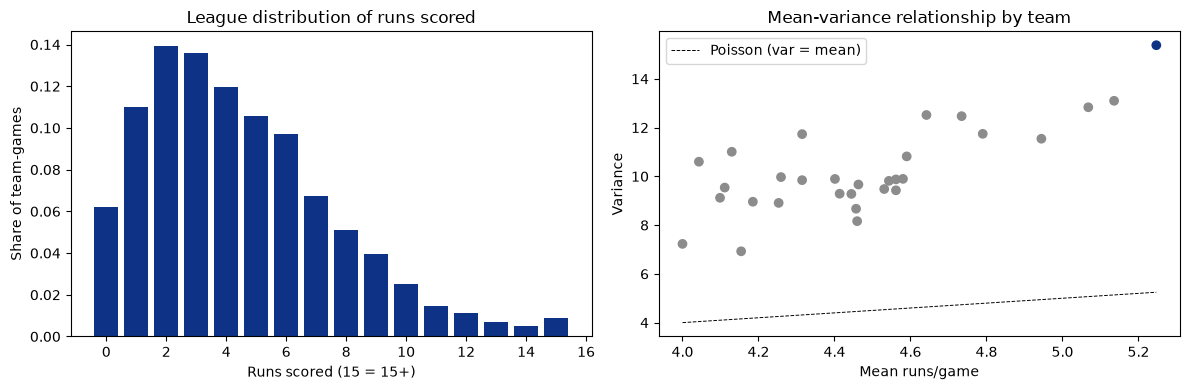

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = games.runs.clip(upper=15).value_counts(normalize=True).sort_index()
axes[0].bar(counts.index, counts.values, color="#0E3386")
axes[0].set_xlabel("Runs scored (15 = 15+)"); axes[0].set_ylabel("Share of team-games")
axes[0].set_title("League distribution of runs scored")
axes[1].scatter(d.runs_per_game, d.runs_var, c=np.where(d.team == "CHC", "#0E3386", "#8c8c8c"))
xs = np.linspace(d.runs_per_game.min(), d.runs_per_game.max(), 20)
axes[1].plot(xs, xs, "k--", lw=0.7, label="Poisson (var = mean)")
axes[1].set_xlabel("Mean runs/game"); axes[1].set_ylabel("Variance")
axes[1].set_title("Mean-variance relationship by team"); axes[1].legend()
plt.tight_layout()
print("mean dispersion index (var/mean):", round(d.dispersion_index.mean(), 2))
print("corr(mean, variance):", round(d.runs_per_game.corr(d.runs_var), 3), "| corr(mean, CV):", round(d.runs_per_game.corr(d.runs_cv), 3))

## 3. Runs-to-wins curve (mechanism)

{'mean_gain_low_runs': 0.12801556420233462, 'mean_gain_high_runs': 0.06508788407352746}


,bucket,games,wins,win_pct,ci_lo,ci_hi,marginal_gain
0,0,301,0,0.0,0.000,0.013,<NA>
1,1,535,44,0.082,0.062,0.109,0.082
2,2,677,159,0.235,0.204,0.268,0.153
3,3,661,256,0.387,0.351,0.425,0.152
4,4,582,316,0.543,0.502,0.583,0.156
5,5,514,329,0.64,0.598,0.680,0.097
6,6,472,337,0.714,0.672,0.753,0.074
7,7,327,255,0.78,0.732,0.821,0.066
8,8,248,223,0.899,0.855,0.931,0.119
9,9,193,174,0.902,0.851,0.936,0.002


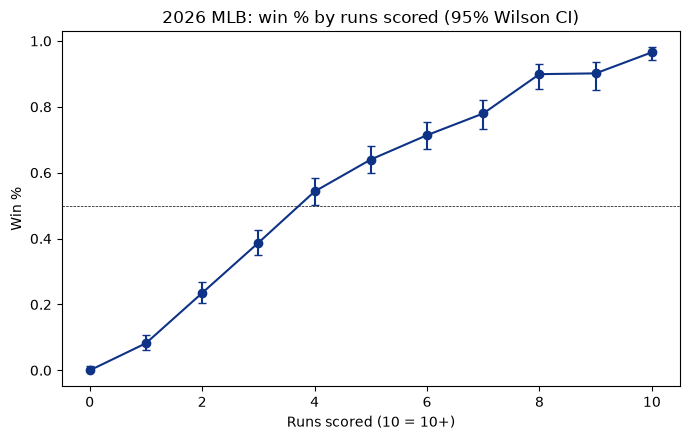

In [4]:
curve = H.runs_to_wins(games)
plots.plot_runs_to_wins(curve)
print(H.concavity_summary(curve))
curve.round(3)

## 4. Fly-ball profile across teams

In [5]:
cols = ["team", "batted_balls", "fb_pct", "gb_pct", "ld_pct", "pu_pct", "mean_la", "barrel_pct", "pull_air_pct"]
d.sort_values("fb_pct", ascending=False)[cols].round(3).reset_index(drop=True)

,team,batted_balls,fb_pct,gb_pct,ld_pct,pu_pct,mean_la,barrel_pct,pull_air_pct
0,DET,4094,0.267,0.383,0.238,0.112,16.024,0.082,0.293
1,LAD,4238,0.263,0.406,0.234,0.097,14.876,0.086,0.286
2,CHC,4268,0.261,0.411,0.208,0.12,15.681,0.076,0.308
3,CIN,3804,0.261,0.405,0.223,0.111,15.586,0.094,0.278
4,KCR,4232,0.253,0.42,0.216,0.111,14.52,0.081,0.283
5,MIN,4225,0.25,0.415,0.219,0.116,15.053,0.078,0.306
6,ATL,4205,0.249,0.425,0.217,0.108,14.301,0.086,0.278
7,NYM,4154,0.249,0.439,0.214,0.098,12.996,0.086,0.276
8,CHW,3987,0.248,0.426,0.219,0.107,13.62,0.084,0.304
9,NYY,3892,0.248,0.407,0.229,0.116,15.063,0.096,0.316


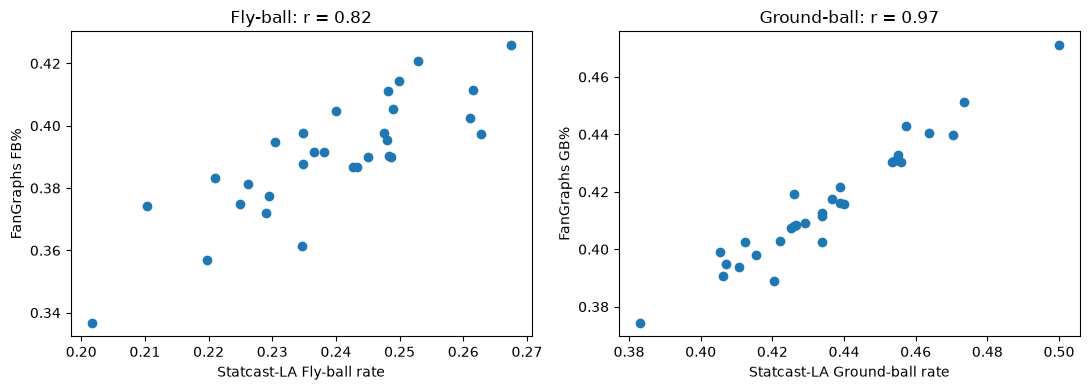

In [6]:
fg = pd.read_csv(ROOT / "data/external/fangraphs-team-batted-ball-2026.csv").set_index("Team")
m = d.set_index("team").join(fg)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (mine, theirs, name) in zip(axes, [("fb_pct", "FB%", "Fly-ball"), ("gb_pct", "GB%", "Ground-ball")], strict=True):
    ax.scatter(m[mine], m[theirs]); ax.set_xlabel(f"Statcast-LA {name} rate"); ax.set_ylabel(f"FanGraphs {theirs}")
    ax.set_title(f"{name}: r = {m[mine].corr(m[theirs]):.2f}")
plt.tight_layout()

## 5. Correlations among exposure candidates and outcomes
Exposure metrics overlap heavily, so the 'robustness' specs are not independent evidence.

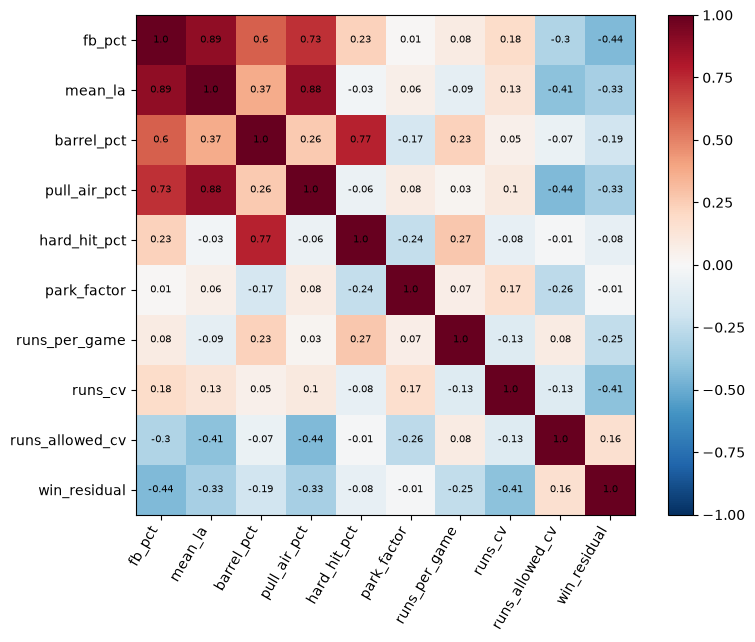

In [7]:
corr_cols = ["fb_pct", "mean_la", "barrel_pct", "pull_air_pct", "hard_hit_pct", "park_factor", "runs_per_game", "runs_cv", "runs_allowed_cv", "win_residual"]
c = d[corr_cols].corr().round(2)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=60, ha="right")
ax.set_yticks(range(len(c))); ax.set_yticklabels(c.columns)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, c.iloc[i, j], ha="center", va="center", fontsize=7)
fig.colorbar(im); plt.tight_layout()

## 6. Run-scoring CV: precision and outliers
Bootstrap intervals are wide relative to between-team spread, which limits H1 power.

mean CI width: 0.172 | between-team SD of CV: 0.043


,team,runs_cv,z
13,LAA,0.81,2.15
24,SFG,0.80,2.11
18,NYM,0.79,1.89


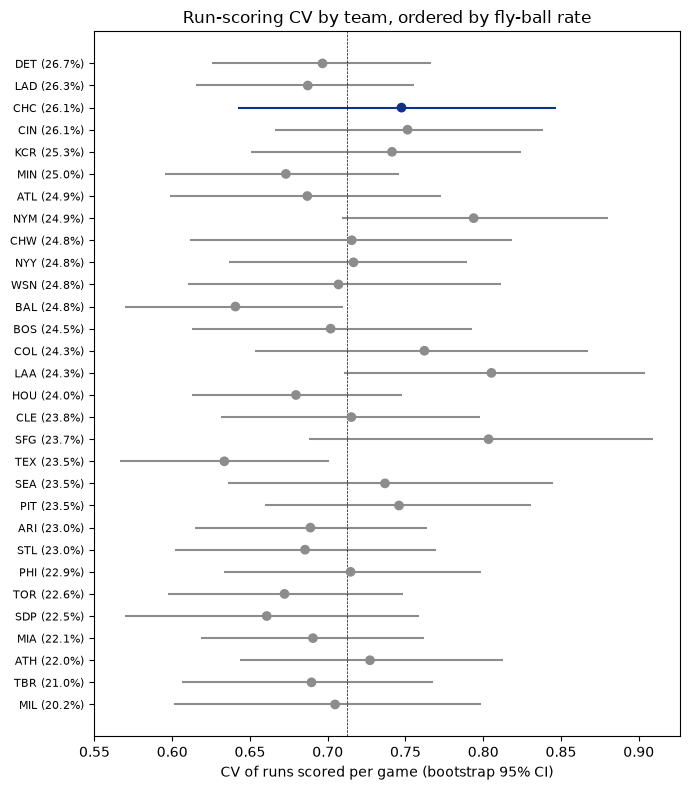

In [8]:
plots.plot_cv_intervals(d)
width = (d.runs_cv_hi - d.runs_cv_lo)
print("mean CI width:", round(width.mean(), 3), "| between-team SD of CV:", round(d.runs_cv.std(), 3))
d.assign(z=(d.runs_cv - d.runs_cv.mean()) / d.runs_cv.std()).nlargest(3, "z")[["team", "runs_cv", "z"]].round(2)

## 7. Key relationships

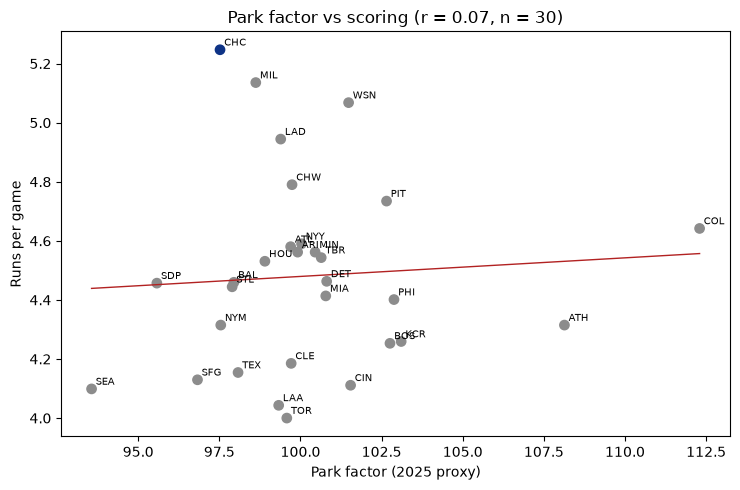

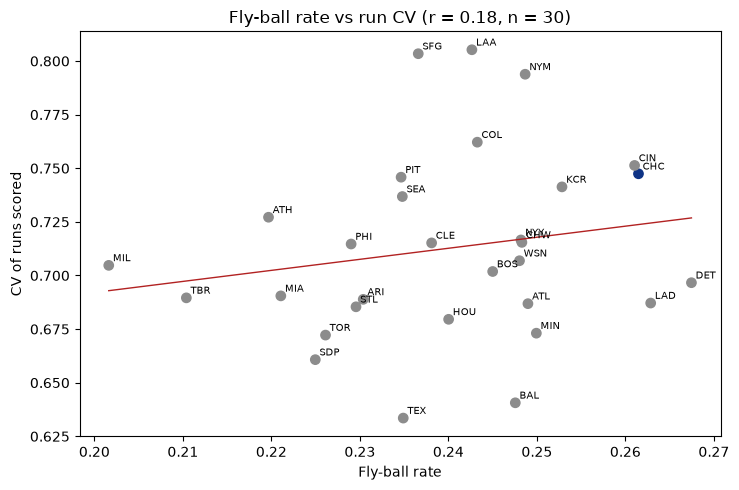

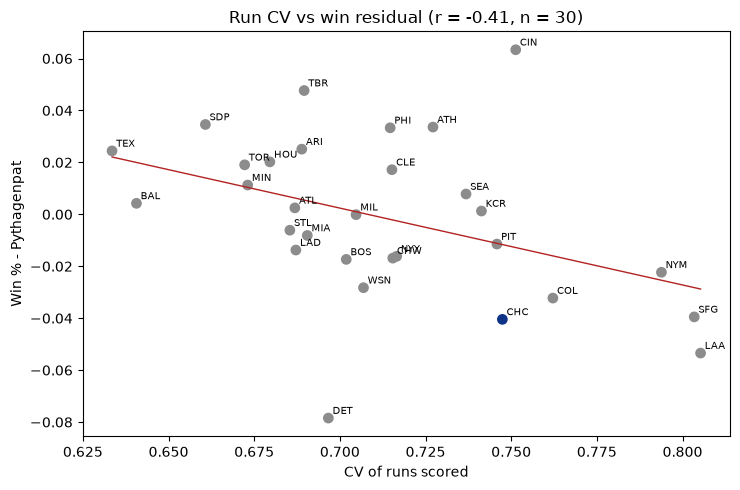

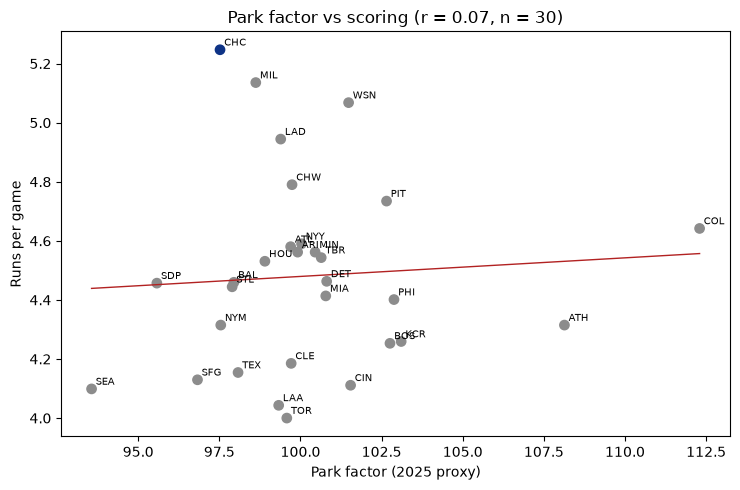

In [9]:
plots.scatter_with_fit(d, "fb_pct", "runs_cv", "Fly-ball rate", "CV of runs scored", "Fly-ball rate vs run CV")
plots.scatter_with_fit(d, "runs_cv", "win_residual", "CV of runs scored", "Win % - Pythagenpat", "Run CV vs win residual")
plots.scatter_with_fit(d, "park_factor", "runs_per_game", "Park factor (2025 proxy)", "Runs per game", "Park factor vs scoring")

## 8. Cubs snapshot (ranks of 30)

In [10]:
metrics = ["fb_pct", "mean_la", "barrel_pct", "runs_per_game", "runs_cv", "runs_allowed_cv", "win_pct", "win_residual"]
ranks = d.set_index("team")[metrics].rank(ascending=False).astype(int)
pd.DataFrame({"CHC": d.set_index("team").loc["CHC", metrics].round(3), "rank (1 = highest)": ranks.loc["CHC"]})

,CHC,rank (1 = highest)
fb_pct,0.261,3
mean_la,15.681,2
barrel_pct,0.076,16
runs_per_game,5.247,1
runs_cv,0.747,6
runs_allowed_cv,0.699,18
win_pct,0.549,7
win_residual,-0.04,28


## 9. Playoff vs non-playoff teams
Descriptive only (12 vs 18 teams, no multiple-comparison adjustment). Playoff list: `data/external/playoff-teams-2026.csv`.

,metric,playoff_mean,non_playoff_mean,diff,ci_lo,ci_hi,p,n_playoff
0,win_pct,0.563,0.458,0.104,0.071,0.138,0.000,12
1,runs_per_game,4.638,4.376,0.262,0.021,0.502,0.034,12
2,runs_allowed_per_game,4.087,4.744,-0.657,-0.955,-0.359,0.000,12
3,runs_cv,0.702,0.720,-0.018,-0.047,0.011,0.205,12
4,runs_allowed_cv,0.745,0.686,0.059,0.029,0.089,0.000,12
5,fb_pct,0.238,0.241,-0.002,-0.015,0.011,0.721,12
6,shutout_rate,0.060,0.063,-0.003,-0.020,0.015,0.736,12
7,win_residual,0.004,-0.005,0.009,-0.014,0.032,0.413,12


,team,wins,runs_per_game,runs_allowed_per_game,runs_cv,fb_pct,win_residual
16,MIL,103,5.136,3.815,0.705,0.202,-0.000
14,LAD,100,4.944,3.704,0.687,0.263,-0.014
26,TBR,98,4.543,4.012,0.690,0.21,0.048
2,ATL,94,4.580,3.864,0.687,0.249,0.002
19,NYY,93,4.590,3.733,0.717,0.248,-0.016
22,SDP,91,4.457,4.204,0.661,0.225,0.035
5,CHC,89,5.247,4.340,0.747,0.261,-0.040
20,PHI,88,4.401,4.309,0.715,0.229,0.033
4,BOS,87,4.253,3.772,0.702,0.245,-0.017
8,CLE,85,4.185,4.117,0.715,0.238,0.017


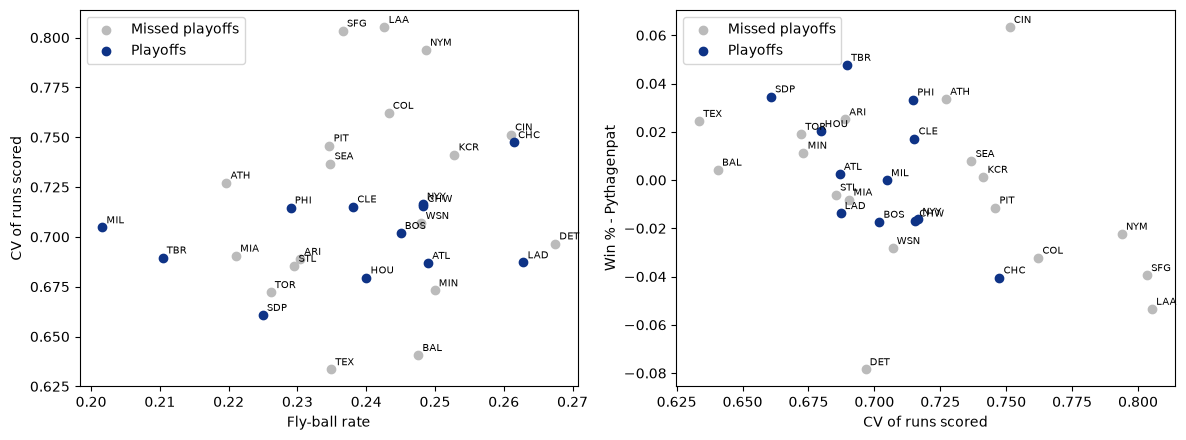

In [11]:
po = H.load_playoff_teams(str(ROOT / "data/external/playoff-teams-2026.csv"))
display(H.compare_playoff(d, po).round(3))

d["playoff"] = d.team.isin(po)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (x, y, xl, yl) in zip(
    axes,
    [("fb_pct", "runs_cv", "Fly-ball rate", "CV of runs scored"), ("runs_cv", "win_residual", "CV of runs scored", "Win % - Pythagenpat")],
    strict=True,
):
    ax.scatter(d.loc[~d.playoff, x], d.loc[~d.playoff, y], c="#bbbbbb", label="Missed playoffs")
    ax.scatter(d.loc[d.playoff, x], d.loc[d.playoff, y], c="#0E3386", label="Playoffs")
    for _, r in d.iterrows():
        ax.annotate(r.team, (r[x], r[y]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend()
plt.tight_layout()
d[d.playoff].sort_values("win_pct", ascending=False)[["team", "wins", "runs_per_game", "runs_allowed_per_game", "runs_cv", "fb_pct", "win_residual"]].round(3)

## Takeaways

- Data checks pass: 30 teams, runs scored equal runs allowed league-wide, no missing values.
- Runs-to-wins is concave, so the mechanism is plausible.
- Run CV is estimated imprecisely (CI width is large relative to between-team spread), so H1 has low power at n = 30.
- Exposure metrics (FB%, mean LA, barrel%) are correlated; robustness checks overlap.
- Park factors are 2025 values (proxy for 2026).
- Playoff teams differ from the rest mainly in run prevention, not in scoring CV or fly-ball rate (differences not significant).